In [1]:
import pandas as pd
import numpy as np
import seaborn as sn
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

## Пункт 1

In [2]:
events = pd.read_excel('NHL-playoffs-2026.xlsx').drop(columns='Unnamed: 0')
events.shape

(29710, 38)

`Unnamed: 0` содержит сохранённый в Excel индекс событий. Удаляем этот столбец, чтобы после чтения pandas создал свой индекс

In [3]:
events.iloc[:10, [2, 3, 4, 9, 12]]

,Date,Away Team,Home Team,Remaining Time,Play Type
0,2026-04-19,Boston Bruins,Buffalo Sabres,20:00,period-start
1,2026-04-19,Boston Bruins,Buffalo Sabres,20:00,faceoff
2,2026-04-19,Boston Bruins,Buffalo Sabres,19:47,hit
3,2026-04-19,Boston Bruins,Buffalo Sabres,19:46,hit
4,2026-04-19,Boston Bruins,Buffalo Sabres,19:41,hit
5,2026-04-19,Boston Bruins,Buffalo Sabres,19:27,hit
6,2026-04-19,Boston Bruins,Buffalo Sabres,19:03,hit
7,2026-04-19,Boston Bruins,Buffalo Sabres,18:53,missed-shot
8,2026-04-19,Boston Bruins,Buffalo Sabres,18:48,hit
9,2026-04-19,Boston Bruins,Buffalo Sabres,18:37,missed-shot


## Пункт 2

In [4]:
def outcome(x):
    OT = x.max() - 3
    if OT <= 0:
        return 'Final'
    elif OT == 1:
        return 'Final/OT'
    else:
        return 'Final/' + str(OT) + 'OT'

После трёх основных периодов каждый следующий период является овертаймом. Отдельная ветка `elif` для одного овертайма нужна, чтобы получить `Final/OT`, а не
`Final/1OT`


In [5]:
games = events.groupby(
    ['Game ID', 'Date', 'Away Team', 'Home Team'],
    as_index=False
).agg(
    Away_Score=('Cumulated Away Score', 'max'),
    Home_Score=('Cumulated Home Score', 'max'),
    Outcome=('Period', outcome)
).rename(columns={
    'Away_Score': 'Away Score',
    'Home_Score': 'Home Score'
}).set_index('Game ID').sort_index()

Каждому `Game ID` соответствуют одна дата и по одной команде, поэтому оставляем эти
поля внутри `groupby`. С помощью `as_index=False` получаем обычные столбцы, а затем
задаём в конце единственный индекс `Game ID` через `set_index`.

Счёт в исходных данных накопительный: складывать его по событиям нельзя.
С помощью `max` выбираем наибольшее значение внутри матча.

В именованных аргументах `agg` удобно сначала использовать названия с нижним
подчёркиванием, а затем переименовать столбцы, так как `agg` не допускает названия переменных с пробелом

In [6]:
games.columns

Index(['Date', 'Away Team', 'Home Team', 'Away Score', 'Home Score',
       'Outcome'],
      dtype='str')

In [7]:
games.iloc[-5:, -4:]

,Home Team,Away Score,Home Score,Outcome
Game ID,,,,
2025030412,Carolina Hurricanes,3,4,Final/OT
2025030413,Vegas Golden Knights,4,5,Final/2OT
2025030414,Vegas Golden Knights,5,3,Final
2025030415,Carolina Hurricanes,2,4,Final
2025030416,Vegas Golden Knights,3,0,Final


## Пункт 3

In [8]:
def gameInfo(gameId):
    game = games.loc[gameId]
    print (
        f"{game['Home Team']} - {game['Away Team']} "
        f"({game['Home Score']} - {game['Away Score']}, "
        f"{game['Outcome']}, {game['Date']})"
    )

In [9]:
gameInfo(games.index.min())
gameInfo(games.index.max())

Buffalo Sabres - Boston Bruins (4 - 3, Final, 2026-04-19)
Vegas Golden Knights - Carolina Hurricanes (0 - 3, Final, 2026-06-14)


Через `loc` получаем строку матча, а f-строка собирает строку в читаемый формат из примера. Для вывода без кавычек используем `print` внутри функции


## Пункт 4

In [10]:
games['Total Score'] = games['Home Score'] + games['Away Score']
games['Total Score'].describe()

count    82.000000
mean      5.926829
std       2.259578
min       1.000000
25%       5.000000
50%       6.000000
75%       7.000000
max      15.000000
Name: Total Score, dtype: float64

Просто складываем два столбца


## Пункт 5

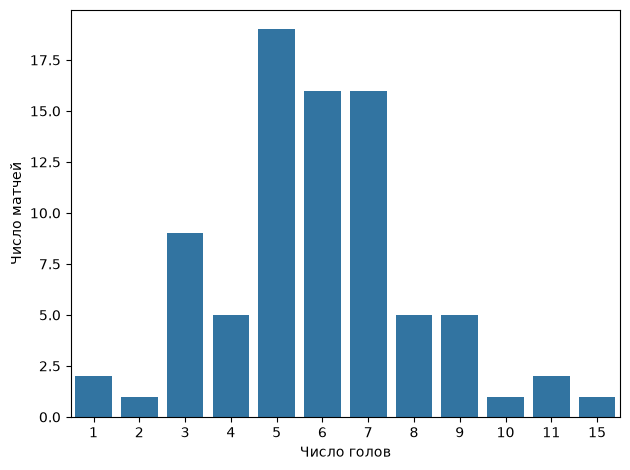

In [11]:
sn.countplot(data=games, x='Total Score')
plt.xlabel('Число голов')
plt.ylabel('Число матчей')
plt.tight_layout()
plt.show()

Чаще всего в матче забивали 5 голов: таких игр 19. По 16 игр завершились с 6 и 7 голами. На результаты от 5 до 7 голов приходится большинство матчей. Распределение имеет правый хвост, который особенно вытягивает матч с 15 голами

По форме распределения нельзя заключить ни его вид (мало наблюдений), ни его необычный характер (нужно сравнивать с другими сезонами)

## Пункт 6

Перепишем функцию `gameinfo`, заменив `print` на `return`

In [12]:
def gameInfo2(gameId):
    game = games.loc[gameId]
    return (
        f"{game['Home Team']} - {game['Away Team']} "
        f"({game['Home Score']} - {game['Away Score']}, "
        f"{game['Outcome']}, {game['Date']})"
)

In [13]:
worstgames = [
    gameInfo2(i)
    for i in games.index[games['Total Score'] == games['Total Score'].min()]
]
worstgames


['Montréal Canadiens - Tampa Bay Lightning (0 - 1, Final/OT, 2026-05-01)',
 'Philadelphia Flyers - Pittsburgh Penguins (1 - 0, Final/OT, 2026-04-29)']

In [14]:
bestgames = [
    gameInfo2(i)
    for i in games.index[games['Total Score'] == games['Total Score'].max()]
]
bestgames


['Colorado Avalanche - Minnesota Wild (9 - 6, Final, 2026-05-03)']

Условие выбирает индексы всех игр с минимальным или максимальным числом голов. Дальше подставляем их в `gameInfo2` с помощью генератора списка

## Пункт 7

Для каждой команды берём шесть столбцов игроков на льду и отдельный столбец вратаря. Столбцы для автоматизации находим с помощью генератора счетчика. 

In [15]:
awayplayers = [
    i for i in events.columns
    if i.startswith("Away Team's Player") or i == "Away Team's Goalie"
]
homeplayers = [
    i for i in events.columns
    if i.startswith("Home Team's Player") or i == "Home Team's Goalie"
]

In [16]:
player_games = events[['Game ID'] + awayplayers + homeplayers].melt(
    id_vars='Game ID', value_name='Player'
)[['Game ID', 'Player']].dropna(subset=['Player']).drop_duplicates()

playercount = player_games.groupby('Game ID')['Player'].nunique()
playerinfo = pd.DataFrame({
    'Game Info': [gameInfo2(i) for i in games.index],
    'Player Count': playercount
}, index=games.index)

playerinfo[playerinfo['Player Count'] == playerinfo['Player Count'].max()]

,Game Info,Player Count
Game ID,,
2025030216,"Montréal Canadiens - Buffalo Sabres (3 - 8, Fi...",40


`melt` собирает имена из всех выбранных столбцов в один столбец `Player`.
Удаляем пропуски и повторяющиеся пары «матч - игрок», затем считаем игроков
внутри матча. Таблица `player_games` пригодится и для пунктов 19-20: она
учитывает участие даже без единого броска или силового приёма.

**Уточнение к примеру экзамена:** в приложенном файле максимум равен **40**,
в матче Montréal Canadiens - Buffalo Sabres 2026-05-16. Здесь по 20 уникальных
имён у каждой команды. Если включить `NaN` в список уникальных значений, можно
получить показанные в примере 41. Пропуск не является игроком.


## Пункт 8

In [17]:
shot_types = ['shot-on-goal', 'goal', 'missed-shot']
shots = events[events['Play Type'].isin(shot_types)].copy()

home_shot = shots['Team Making the Play'] == shots['Home Team']
home_defends_left = shots["Home Team's Defending Side"] == 'left'
goal_x = np.where(home_shot == home_defends_left, 89, -89)

dx = shots['X Coordinate on the Ice Rink'] - goal_x
dy = (shots['Y Coordinate on the Ice Rink'].abs() - 3).clip(lower=0)
shots['Shot Length'] = np.hypot(dx, dy)

events.loc[shots.index, 'Shot Length'] = shots['Shot Length']
shots[['Game ID', 'Play Type', 'Shot Length']]

,Game ID,Play Type,Shot Length
7,2025030111,missed-shot,12.206556
9,2025030111,missed-shot,12.000000
12,2025030111,missed-shot,29.410882
13,2025030111,shot-on-goal,62.169124
19,2025030111,missed-shot,52.924474
...,...,...,...
29695,2025030416,missed-shot,54.083269
29696,2025030416,missed-shot,5.099020
29704,2025030416,goal,46.238512
29706,2025030416,missed-shot,60.926185


Если хозяева защищают левые ворота, то они бросают по правым, а гости по левым.
При защите правых ворот всё наоборот. Условие `home_shot == home_defends_left`
выбирает два случая броска по правым воротам.

Створ расположен между $y=-3$ и $y=3$. Поэтому расстояние по вертикали до
ближайшей точки створа равно $\max(|y|-3, 0)$, а полное расстояние:

$$d=\sqrt{(x-X)^2+\max(|y|-3,0)^2}.$$

`np.hypot(dx, dy)` вычисляет эту формулу сразу для всех строк. Расстояние
измеряется в футах. Считаем его для 7 266 бросков; `blocked-shot` в этот пункт
не входит. События `goal` тоже относятся к точным броскам.


## Пункт 9

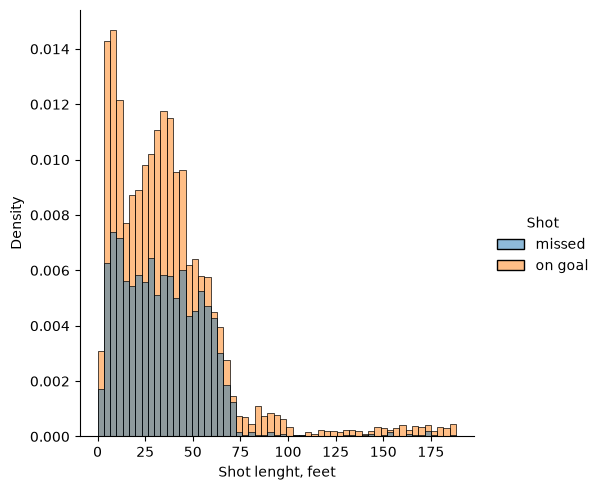

In [18]:
shots['Shot'] = np.where(shots['Play Type'].isin(['shot-on-goal', 'goal']), 'on goal', 'missed')

graph=sn.displot(data=shots, x='Shot Length', hue='Shot', hue_order=['missed', 'on goal'], stat='density', common_norm='False')
graph.set_axis_labels('Shot lenght, feet', 'Density')
plt.show()

In [19]:
shots.groupby('Shot')['Shot Length'].agg(['count', 'mean', 'median', 'max'])

,count,mean,median,max
Shot,,,,
missed,2643,34.013562,32.249031,185.067555
on goal,4623,36.206558,31.827661,188.215302


Точных бросков 4 623, неточных 2 643. `stat='density'` вместе с `common_norm=False` нормирует каждое распределение отдельно, так что площадь каждой гистограммы равна единице. Это позволяет сравнивать форму распределений при разных размерах групп

Обе группы в основном сосредоточены на небольших расстояниях. У точных бросков медиана чуть ниже: 31,828 против 32,249 фута. Но их средняя длина выше: 36,207 против 34,014 фута из-за более длинного правого хвоста

Возможное объяснение хвоста точных бросков: дальние забросы со своей половины, которые доходят до вратаря и регистрируются как броски в створ. Также возможны дальние броски по пустым воротам

## Пункт 10

In [20]:
numshots = shots.groupby(
    ['Game ID', 'Team Making the Play']
)['Play Type'].value_counts().unstack(fill_value=0).reindex(
    columns=shot_types, fill_value=0
)

numshots['Shots on Goal'] = numshots['shot-on-goal'] + numshots['goal']
numshots['Unblocked Shots'] = numshots['Shots on Goal'] + numshots['missed-shot']
numshots['Share of Shots on Goal'] = (numshots['Shots on Goal'] / numshots['Unblocked Shots'])
numshots['Share of Shots on Goal']

Game ID     Team Making the Play
2025030111  Boston Bruins           0.625000
            Buffalo Sabres          0.678571
2025030112  Boston Bruins           0.613636
            Buffalo Sabres          0.636364
2025030113  Boston Bruins           0.694444
                                      ...   
2025030414  Vegas Golden Knights    0.583333
2025030415  Carolina Hurricanes     0.558140
            Vegas Golden Knights    0.510204
2025030416  Carolina Hurricanes     0.638889
            Vegas Golden Knights    0.594595
Name: Share of Shots on Goal, Length: 164, dtype: float64

Считаем отдельно для каждой пары «игра - команда». `unstack` переносит типы бросков в столбцы, а `fill_value=0` сохраняет нули там, где событий данного типа не было. Заблокированные броски исключены из знаменателя по условию

Получаем 164 наблюдения. Средняя доля по этим наблюдениям около 63,9%, минимум 35,3%, максимум 86,0%. Вывод: точность заметно меняется от матча к матчу

## Пункт 11

In [21]:
avgnumshots = numshots['Share of Shots on Goal'].groupby(
    'Team Making the Play'
).mean()

avgnumshots.nlargest(5)

Team Making the Play
Edmonton Oilers        0.706232
Philadelphia Flyers    0.683668
Dallas Stars           0.670142
Minnesota Wild         0.656099
Colorado Avalanche     0.652559
Name: Share of Shots on Goal, dtype: float64

In [22]:
avgnumshots.nsmallest(5)

Team Making the Play
Pittsburgh Penguins    0.554046
Utah Mammoth           0.599298
Carolina Hurricanes    0.614844
Tampa Bay Lightning    0.625713
Buffalo Sabres         0.625838
Name: Share of Shots on Goal, dtype: float64

Берём среднее матчевых долей: каждый сыгранный матч получает одинаковый вес. Отношение суммарных точных бросков к суммарным незаблокированным броскам было бы другим показателем, в котором матчи с большим числом бросков весят больше

Самая высокая средняя доля у Edmonton Oilers, около 70,6%, самая низкая у
Pittsburgh Penguins, около 55,4%, разница составляет 15,2%. Высокая точность сама по себе не означает больше голов: имеют значение число и качество бросков, а также игра вратаря

## Пункт 12

In [23]:
avgshots = numshots[['Shots on Goal', 'goal']].rename(columns={
    'Shots on Goal': 'Shot',
    'goal': 'Goal'
}).groupby('Team Making the Play').mean()

avgshots

Play Type,Shot,Goal
Team Making the Play,,
Anaheim Ducks,31.666667,3.250000
Boston Bruins,25.166667,2.000000
Buffalo Sabres,30.461538,3.307692
Carolina Hurricanes,31.631579,3.473684
Colorado Avalanche,32.153846,3.384615
Dallas Stars,31.000000,2.500000
Edmonton Oilers,28.333333,3.500000
Los Angeles Kings,25.250000,1.250000
Minnesota Wild,28.727273,3.727273


В `Shot` входят и отражённые броски, и голы. Сначала у нас уже есть счётчики для каждого матча команды, включая нули по голам, затем берём среднее. Поэтому матчи без голов не теряются из знаменателя.

## Пункт 13

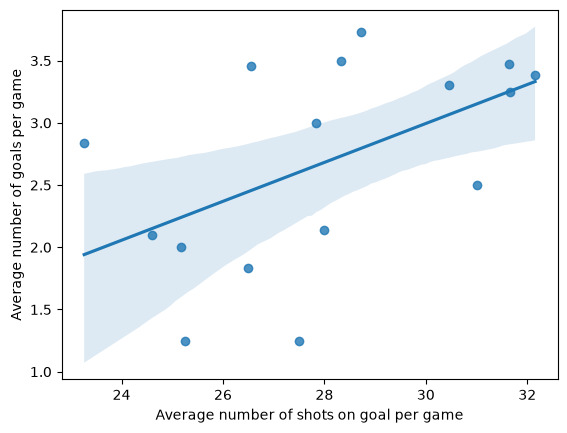

In [24]:
graph2=sn.regplot(data=avgshots, x='Shot', y='Goal')

graph2.set_xlabel('Average number of shots on goal per game')
graph2.set_ylabel('Average number of goals per game')
plt.show()

Видна умеренная положительная связь. Команды с большим средним числом бросков в створ в среднем забивают больше, но разброс значителен.

Это описание 16 команд данного плей-офф, у которых разное число сыгранных матчей. Каждая команда представлена одной точкой с одинаковым весом. Лишь одна линия регрессии не доказывает причинное влияние числа бросков на голы.

## Пункт 14

In [25]:
attempt_types = ['goal', 'shot-on-goal', 'missed-shot', 'blocked-shot']
attempts = events[events['Play Type'].isin(attempt_types)].copy()
attempts_per_game = attempts.groupby('Game ID').size()
mostshots = attempts_per_game.idxmax()

gameInfo(mostshots)

Carolina Hurricanes - Ottawa Senators (3 - 2, Final/2OT, 2026-04-20)


Включаем все четыре исхода броска. Здесь `.size()` считает строки, то есть отдельные события, а `idxmax()` возвращает ID игры с максимальным счётчиком.

## Пункт 15

In [26]:
from rink import plot_rink

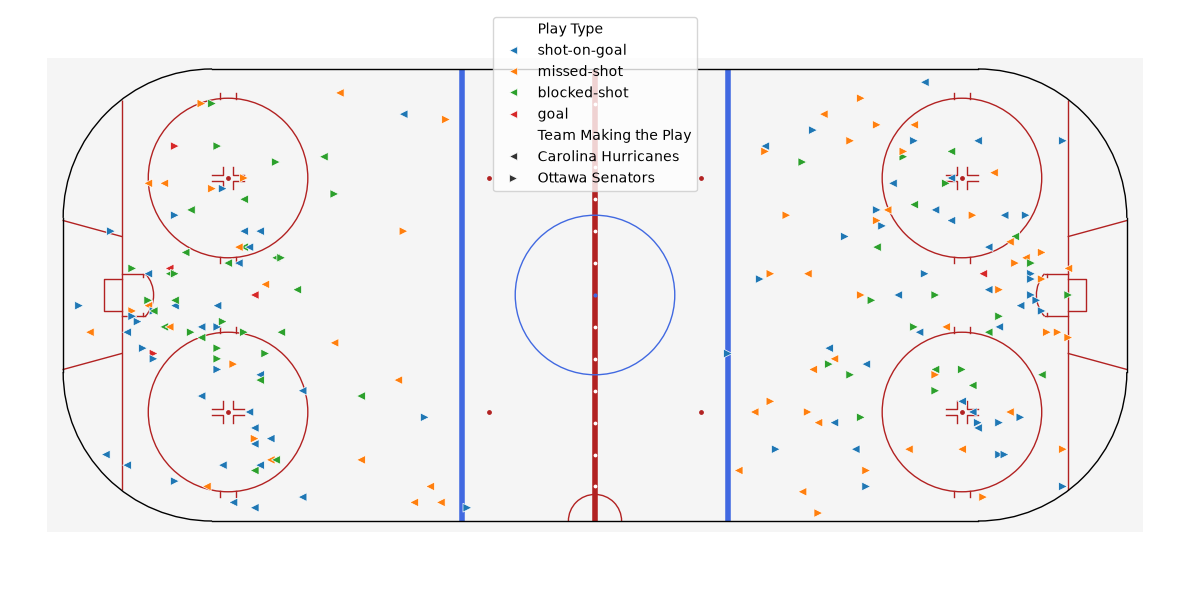

In [27]:
game_shots = attempts[attempts['Game ID'] == mostshots].copy()

coordinates = ['X Coordinate on the Ice Rink', 'Y Coordinate on the Ice Rink']
odd_periods = game_shots['Period'] % 2 == 1
game_shots.loc[odd_periods, coordinates] *= 1

plt.figure(figsize=(12,6))
plot_rink()

sn.scatterplot(
    data=game_shots, 
    x=coordinates[0],
    y=coordinates[1],
    hue='Play Type',
    style='Team Making the Play',
    markers=('<','>'),
    s=40, 
)

plt.axis('equal')
plt.axis('off')
plt.legend(loc='upper center')
plt.tight_layout()
plt.show()

## Пункт 16

In [28]:
goals = events[events['Play Type'] == 'goal'].copy()
playergoals = goals['Player in the Event #1'].value_counts().rename('Goals')
playergoals.index.name = 'Player'

playergoals.sort_index().nlargest(10)

Player
Brett Howden       14
Pavel Dorofeyev    12
Logan Stankoven    11
Mitch Marner       10
Jordan Staal        8
Nikolaj Ehlers      8
Alex Newhook        7
Jackson Blake       7
Mark Stone          7
Matt Boldy          7
Name: Goals, dtype: int64

Для события `goal` первый игрок является автором гола. `value_counts()` считает число таких событий для каждого игрока. 

Здесь и в следующих рейтингах выводим ровно десять игроков. При равенстве показателя приоритет задаётся алфавитным порядком имён: для этого перед `nlargest(10)` используем `sort_index()`. Другие игроки с таким же результатом на границе десятки могут остаться за её пределами

## Пункт 17

In [29]:
assists = goals[['Player in the Event #2', 'Player in the Event #3']].melt(
    value_name='Player'
)['Player'].dropna()
playerassists = assists.value_counts().rename('Assists')
playerassists.index.name = 'Player'

playerassists.sort_index().nlargest(10)

Player
Jack Eichel        20
Mitch Marner       19
Jackson Blake      13
Lane Hutson        13
Martin Necas       12
Nick Suzuki        12
Shea Theodore      12
Taylor Hall        12
Kirill Kaprizov    11
Quinn Hughes       11
Name: Assists, dtype: int64

За один гол могут быть начислены две передачи. Поэтому объединяем оба столбца ассистентов в один и убираем пропуски, но не удаляем повторения имён: каждое повторение означает ещё одну передачу


## Пункт 18

In [30]:
playerpoints = playergoals.add(playerassists, fill_value=0).astype(int)
playerpoints.name = 'Points'
top_points = playerpoints.sort_index().nlargest(10)

playerassists.sort_index().nlargest(10)

Player
Jack Eichel        20
Mitch Marner       19
Jackson Blake      13
Lane Hutson        13
Martin Necas       12
Nick Suzuki        12
Shea Theodore      12
Taylor Hall        12
Kirill Kaprizov    11
Quinn Hughes       11
Name: Assists, dtype: int64

`add(..., fill_value=0)` складывает голы и передачи по имени игрока. Если игрок есть только в одном из двух счётчиков, отсутствующий результат принимается за ноль

## Пункт 19

In [31]:
playergames = player_games.groupby('Player')['Game ID'].nunique().rename('Games')
playershots = events[
    events['Play Type'].isin(['shot-on-goal', 'goal'])
]['Player in the Event #1'].value_counts().rename('Shots')

shot_average = pd.DataFrame({'Games': playergames, 'Shots': playershots})
shot_average['Shots'] = shot_average['Shots'].fillna(0).astype(int)
shot_average['Shots per Game'] = shot_average['Shots'] / shot_average['Games']
top_shooters = shot_average['Shots per Game'].sort_index().nlargest(10).index

top_shooters

Index(['Jason Robertson', 'Dylan Guenther', 'Nikita Kucherov', 'Matt Boldy',
       'Quinton Byfield', 'Darren Raddysh', 'Joel Eriksson Ek',
       'Alex Laferriere', 'David Pastrnak', 'Nathan MacKinnon'],
      dtype='str')

В знаменателе стоит число матчей, в которых сам игрок выходил на лёд. Делить на число матчей всей команды или только на матчи с броском было бы неправильно. Голы тоже считаются бросками в створ

## Пункт 20

In [32]:
playerhits = events[
    events['Play Type'] == 'hit'
]['Player in the Event #1'].value_counts().rename('Hits')

hit_average = pd.DataFrame({'Games': playergames, 'Hits': playerhits})
hit_average['Hits'] = hit_average['Hits'].fillna(0).astype(int)
hit_average['Hits per Game'] = hit_average['Hits'] / hit_average['Games']
top_hitters = hit_average['Hits per Game'].sort_index().nlargest(10).index

top_hitters

Index(['Lawson Crouse', 'Alex Turcotte', 'Alexander Petrovic', 'Yakov Trenin',
       'Dylan Cozens', 'Vasily Podkolzin', 'Carl Grundstrom', 'Ivan Barbashev',
       'Marcus Foligno', 'Owen Tippett'],
      dtype='str')

Для `hit` игрок №1 проводит силовой приём, а игрок №2 его принимает. Считаем только первого. Число сыгранных матчей берём из уже построенной таблицы участия, включая матчи без силовых приёмов

## Пункт 21

Нужно считать голы, пропущенные конкретным вратарём, а не его командой за весь матч. Вратарь мог выйти на замену и не пропустить, хотя команда до этого уже пропустила. Гол в пустые ворота не записываем снятому вратарю

Во всех 22 решающих голах в овертайме пусты все столбцы состава обеих команд, а число игроков равно нулю. Для таких строк используем последнее известное состояние ворот в том же матче и периоде. Предполагаем, что между последним зарегистрированным составом и голом смены вратаря не было. При полном составе и пустом поле вратаря сохраняем факт пустых ворот


In [33]:
goalie_columns = ["Away Team's Goalie", "Home Team's Goalie"]
missing_lineup = events[awayplayers + homeplayers].isna().all(axis=1)
goalie_on_ice = events[goalie_columns].copy()

for column in goalie_columns:
    state = events[column].fillna('Empty net').mask(missing_lineup)
    state = state.groupby([events['Game ID'], events['Period']]).ffill()
    goalie_on_ice[column] = state.replace('Empty net', np.nan)

goal_events = goals.copy()
home_goal = goal_events['Team Making the Play'] == goal_events['Home Team']
goal_events['Goalie'] = np.where(
    home_goal,
    goalie_on_ice.loc[goal_events.index, "Away Team's Goalie"],
    goalie_on_ice.loc[goal_events.index, "Home Team's Goalie"]
)

goalie_games = events[['Game ID'] + goalie_columns].melt(
    id_vars='Game ID', value_name='Goalie'
)[['Game ID', 'Goalie']].dropna(subset=['Goalie']).drop_duplicates()

goals_against = goal_events.groupby(['Game ID', 'Goalie']).size().rename('Goals Against')
goalie_stats = goalie_games.join(goals_against, on=['Game ID', 'Goalie'])
goalie_stats['Goals Against'] = goalie_stats['Goals Against'].fillna(0).astype(int)
zero_against = goalie_stats[goalie_stats['Goals Against'] == 0].copy()

zero_goalies = sorted(zero_against['Goalie'].unique().tolist())
zero_goalies

['Andrei Vasilevskiy',
 'Brandon Bussi',
 'Dan Vladar',
 'Frederik Andersen',
 'Joonas Korpisalo',
 'Scott Wedgewood']

## Пункт 22

**Свой содержательный вопрос: чаще ли побеждает команда, которая нанесла больше бросков?**


Рассмотрим все попытки броска: голы, отражённые, неточные и заблокированные
броски. В каждом матче сравним их количество у хозяев и гостей, затем проверим,
победила ли команда с большим числом попыток. Матчи с равным числом попыток
посчитаем отдельно.


In [34]:
team_attempts = attempts.groupby(['Game ID', 'Team Making the Play']).size()
comparison = games[['Home Team', 'Away Team', 'Home Score', 'Away Score']].copy()

comparison['Home Attempts'] = [
    team_attempts.loc[(i, team)]
    for i, team in zip(comparison.index, comparison['Home Team'])
]
comparison['Away Attempts'] = [
    team_attempts.loc[(i, team)]
    for i, team in zip(comparison.index, comparison['Away Team'])
]

equal_attempts = comparison['Home Attempts'] == comparison['Away Attempts']
decided = comparison[~equal_attempts]
leader_won = (
    (decided['Home Attempts'] > decided['Away Attempts'])
    == (decided['Home Score'] > decided['Away Score'])
)

attempt_result = pd.DataFrame({
    'Результат': [
        'Победила команда с большим числом бросков',
        'Проиграла команда с большим числом бросков',
        'Команды нанесли одинаковое число бросков'
    ],
    'Число матчей': [
        int(leader_won.sum()),
        int((~leader_won).sum()),
        int(equal_attempts.sum())
    ]
}).set_index('Результат')

attempt_result

,Число матчей
Результат,
Победила команда с большим числом бросков,41
Проиграла команда с большим числом бросков,39
Команды нанесли одинаковое число бросков,2


In [35]:
win_share = leader_won.mean()
print(f'Доля побед команды с большим числом бросков: {win_share:.2%}')

Доля побед команды с большим числом бросков: 51.25%


В 80 матчах одна команда нанесла больше бросков, чем другая. Из них она
выиграла 41 раз и проиграла 39 раз: доля побед равна **51,25%**. В двух матчах
число попыток совпало.

В этой выборке простое преимущество по числу всех бросков почти не разделяет
победы и поражения. Это не противоречит пункту 13: там сравнивались средние
броски **в створ** и голы между командами, а здесь все попытки и победа внутри
конкретного матча. Возможные объяснения: уступающая команда может активнее
бросать, а опасность попыток различается. Установить причинное влияние числа
бросков по такому сравнению нельзя.
